In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists('/content/pumpkin_data'):
    !unzip -q "/content/drive/MyDrive/Original Dataset.zip" -d /content/pumpkin_data

Mounted at /content/drive


In [2]:
# Settings from Khaldi & Kalmoun (2024), arXiv 2410.00062
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

IMG, BS, LR, EPOCHS = 224, 8, 1e-5, 50      # 224x224, batch 8, lr 1e-5, 50 epochs
STEP, GAMMA = 5, 0.1                         # lr x0.1 every 5 epochs (MultiStep, best config in the paper)
WD = 1e-4                                    # paper says "Adam with weight decay", value NOT stated
SPLIT = (0.80, 0.10, 0.10)                   # no augmentation (paper's best result was without it)
SPLIT_SEED, SEED = 42, 42                    # SEED: change for repeat runs
OUT = '/content/drive/MyDrive/pumpkin_runs'
os.makedirs(OUT, exist_ok=True)
RUN = f'densenet121_khaldi_seed{SEED}'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print(device)

cuda


In [3]:
def find_root(base):
    for r, dirs, _ in os.walk(base):
        if len(dirs) == 5 and all(any(f.lower().endswith(('.jpg','.jpeg','.png')) for f in os.listdir(os.path.join(r, d))) for d in dirs):
            return r
ROOT = find_root('/content/pumpkin_data')
full = datasets.ImageFolder(ROOT); classes = full.classes
paths  = [os.path.relpath(p, ROOT) for p, _ in full.samples]
labels = np.array([y for _, y in full.samples])

split_file = f'{OUT}/split_801010_seed{SPLIT_SEED}.json'
if os.path.exists(split_file):
    split = json.load(open(split_file))
else:
    idx = np.arange(len(paths))
    tr, tmp = train_test_split(idx, test_size=0.2, stratify=labels, random_state=SPLIT_SEED)
    va, te = train_test_split(tmp, test_size=0.5, stratify=labels[tmp], random_state=SPLIT_SEED)
    split = dict(train=[paths[i] for i in tr], val=[paths[i] for i in va], test=[paths[i] for i in te])
    json.dump(split, open(split_file, 'w'))

tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
ds = datasets.ImageFolder(ROOT, transform=tf)
p2i = {p: i for i, p in enumerate(paths)}
sub = lambda k: Subset(ds, [p2i[p] for p in split[k]])
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(sub('train'), batch_size=BS, shuffle=True, num_workers=2, generator=g)
val_loader   = DataLoader(sub('val'),   batch_size=BS, num_workers=2)
test_loader  = DataLoader(sub('test'),  batch_size=BS, num_workers=2)
print(classes, {k: len(v) for k, v in split.items()})

['Bacterial Leaf Spot', 'Downy Mildew', 'Healthy Leaf', 'Mosaic Disease', 'Powdery_Mildew'] {'train': 1600, 'val': 200, 'test': 200}


In [4]:
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, len(classes))
model = model.to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP, gamma=GAMMA)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train: loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, correct / total

ckpt = f'{OUT}/best_{RUN}.pth'
best_val, hist, t0 = 0.0, [], time.time()
for ep in range(EPOCHS):
    s = time.time()
    tl, ta = run_epoch(train_loader, True); vl, va = run_epoch(val_loader, False)
    scheduler.step()
    saved = va > best_val
    if saved: best_val = va; torch.save(model.state_dict(), ckpt)
    hist.append(dict(epoch=ep+1, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
    print(f"Epoch {ep+1}/{EPOCHS} | train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f} | {time.time()-s:.0f}s{'  <- saved' if saved else ''}")
train_min = (time.time() - t0) / 60
pd.DataFrame(hist).to_csv(f'{OUT}/history_{RUN}.csv', index=False)
print(f'best val acc {best_val:.4f} | {train_min:.1f} min')

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 147MB/s]


Epoch 1/50 | train 1.3014/0.5413 | val 0.9111/0.8050 | 32s  <- saved
Epoch 2/50 | train 0.8144/0.7794 | val 0.6070/0.8300 | 26s  <- saved
Epoch 3/50 | train 0.5970/0.8300 | val 0.4972/0.8250 | 27s
Epoch 4/50 | train 0.5282/0.8387 | val 0.4482/0.8650 | 26s  <- saved
Epoch 5/50 | train 0.4330/0.8688 | val 0.4171/0.8550 | 27s
Epoch 6/50 | train 0.4022/0.8825 | val 0.4241/0.8450 | 26s
Epoch 7/50 | train 0.3797/0.8931 | val 0.4213/0.8350 | 31s
Epoch 8/50 | train 0.3889/0.8825 | val 0.4099/0.8600 | 26s
Epoch 9/50 | train 0.3548/0.8956 | val 0.4085/0.8500 | 26s
Epoch 10/50 | train 0.3664/0.8956 | val 0.4137/0.8650 | 27s
Epoch 11/50 | train 0.3534/0.8944 | val 0.4049/0.8550 | 26s
Epoch 12/50 | train 0.3593/0.8906 | val 0.4174/0.8600 | 26s
Epoch 13/50 | train 0.3763/0.8919 | val 0.4180/0.8600 | 26s
Epoch 14/50 | train 0.3767/0.8844 | val 0.4046/0.8500 | 26s
Epoch 15/50 | train 0.3472/0.8956 | val 0.4039/0.8600 | 26s
Epoch 16/50 | train 0.3624/0.8956 | val 0.4098/0.8400 | 26s
Epoch 17/50 | train

TEST acc 0.8350 | weighted precision 0.8476 recall 0.8350 | macro F1 0.8321   (paper: 86.00 / 86.33 / 86.00)
                     precision    recall  f1-score   support

Bacterial Leaf Spot     0.8000    0.8000    0.8000        40
       Downy Mildew     0.7273    1.0000    0.8421        40
       Healthy Leaf     0.8947    0.8500    0.8718        40
     Mosaic Disease     0.9231    0.9000    0.9114        40
     Powdery_Mildew     0.8929    0.6250    0.7353        40

           accuracy                         0.8350       200
          macro avg     0.8476    0.8350    0.8321       200
       weighted avg     0.8476    0.8350    0.8321       200



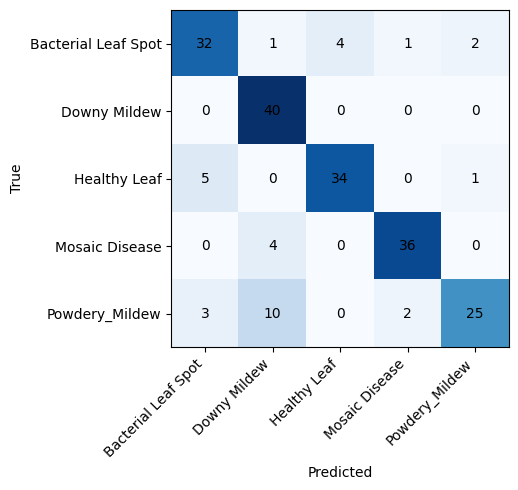

,0
Model,DenseNet-121
Track,A
Seed,42
Split,80/10/10
Split file,/content/drive/MyDrive/pumpkin_runs/split_8010...
Input size,224x224
Epochs,50
Batch size,8
Learning rate,0.00001
Optimizer,"Adam wd=0.0001 (wd not stated), StepLR 5/0.1"


In [5]:
model.load_state_dict(torch.load(ckpt)); model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred += model(x.to(device)).argmax(1).cpu().tolist(); y_true += y.tolist()

acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
prec, rec, f1w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
_, _, f1m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
print(f'TEST acc {acc:.4f} | weighted precision {prec:.4f} recall {rec:.4f} | macro F1 {f1m:.4f}   (paper: 86.00 / 86.33 / 86.00)')
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(classes, rotation=45, ha='right'); ax.set_yticklabels(classes)
for i in range(5):
    for j in range(5): ax.text(j, i, cm[i, j], ha='center', va='center')
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); plt.tight_layout(); plt.savefig(f'{OUT}/cm_{RUN}.png', dpi=150); plt.show()

row = {'Model': 'DenseNet-121', 'Track': 'A', 'Seed': SEED, 'Split': '80/10/10', 'Split file': split_file,
       'Input size': '224x224', 'Epochs': EPOCHS, 'Batch size': BS, 'Learning rate': LR,
       'Optimizer': f'Adam wd={WD} (wd not stated), StepLR {STEP}/{GAMMA}', 'Augmentation': 'None',
       'Best val acc': round(best_val, 4), 'Test acc': round(acc, 4), 'Macro F1': round(f1m, 4),
       'Params (M)': round(n_params, 2), 'Train time (min)': round(train_min, 1),
       'Notebook file': 'pumpkin_densenet121.ipynb', 'Checkpoint path': ckpt}
log = f'{OUT}/run_log.csv'
pd.DataFrame([row]).to_csv(log, mode='a', header=not os.path.exists(log), index=False)
pd.DataFrame([row]).T